# 02 - The zoom audit: do metric depth models respect a digital zoom?

Results come from `scripts/run_audit.py` on Kaggle GPUs:
- main set: 8 runs (7 models + Metric3D with stale K), 200 images per set, 800 per model;
- model ladder: larger variants and newer families (DA3, UniK3D, VGGT), 100 images per set.

Per image we fit two exponents (see `src/analysis.py`):
- **alpha**: depth of the same pixels scales like s^-alpha. Ideal 0. A model that only
  reads apparent size gives 1 (twice as big = twice as close).
- **beta**: predicted focal scales like s^beta. Ideal 1.

Control: the *blur* row degrades the image like a 2x zoom without changing the field
of view. If depth moved as much under blur, interpolation would be the explanation.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as A
import plotstyle as ps

ps.use()
# paper figures drawn at their printed size
SMALL = {"font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "legend.fontsize": 6.5,
         "xtick.labelsize": 6.5, "ytick.labelsize": 6.5}
TAB = ROOT / "outputs/tables"
TAB.mkdir(parents=True, exist_ok=True)
MAIN = ["dav2-s", "dav2-b", "zoedepth", "depthpro", "moge2-s", "unidepth2-s", "metric3d-s", "metric3d-s-staleK"]
LADDER = ["dav2-l", "moge2-b", "moge2-l", "unidepth2-b", "unidepth2-l", "unik3d-l",
          "da3-nested", "da3-metric-l", "metric3d-l", "da3-l", "vggt"]
RELATIVE = {"da3-l", "vggt"}  # depth normalised per scene: only beta is meaningful

df = A.load()
present = set(df.model)
MAIN = [m for m in MAIN if m in present]
LADDER = [m for m in LADDER if m in present]
print(df.groupby(["model", "dataset"]).name.nunique().unstack())

dataset            diode-in  diode-out  kitti  nyu
model                                             
da3-l                    50         50     50   50
da3-metric-l             50         50     50   50
da3-nested               50         50     50   50
dav2-b                  200        200    200  200
dav2-l                  100        100    100  100
dav2-s                  200        200    200  200
dav2-s-anchor           200        200    200  200
dav2-s-blur             200        200    200  200
dav2-s-eft              200        200    200  200
dav2-s-eftb             200        200    200  200
dav2-s-eftb3            200        200    200  200
dav2-s-fixed            200        200    200  200
dav2-s-zhong            200        200    200  200
depthpro                200        200    200  200
metric3d-l               50         50     50   50
metric3d-s              200        200    200  200
metric3d-s-staleK       200        200    200  200
moge2-b                 100    

In [2]:
pi = A.per_image(df[df.model.isin(MAIN + LADDER)])
pi.loc[pi.model.isin(RELATIVE), "alpha"] = np.nan
summ = A.summary(pi).merge(A.blur_control(df).reset_index(), on=["model", "dataset"], how="left")
summ.to_csv(TAB / "audit_by_model_dataset.csv", index=False)

## Table 1: pooled over the four sets

In [3]:
pooled = A.summary(pi, by=("model",)).set_index("model")
pooled["blur2"] = A.blur_control(df).groupby("model").mean()
pooled["alpha_plus_beta"] = pi.assign(ab=pi.alpha + pi.beta).groupby("model").ab.median()
cols = ["n", "alpha", "alpha_lo", "alpha_hi", "beta", "alpha_plus_beta", "die2", "blur2", "absrel1", "absrel3"]
t1 = pooled.loc[[m for m in MAIN + LADDER if m in pooled.index], cols]
t1.index = [ps.LABEL.get(m, m) for m in t1.index]
t1.round(3).to_csv(TAB / "table1_pooled.csv")
t1.round(3)

,n,alpha,alpha_lo,alpha_hi,beta,alpha_plus_beta,die2,blur2,absrel1,absrel3
DA-V2-S,800,0.954,0.925,0.990,NaN,NaN,0.608,0.013,0.317,0.652
DA-V2-B,800,0.852,0.820,0.874,NaN,NaN,0.579,0.008,0.313,0.599
ZoeDepth,800,0.614,0.582,0.639,NaN,NaN,0.438,0.007,0.310,0.539
Depth Pro,800,0.311,0.271,0.336,0.651,0.974,0.253,0.028,0.310,0.459
MoGe-2-S,800,0.363,0.337,0.382,0.558,0.945,0.244,0.031,0.274,0.465
UniDepthV2-S,800,0.343,0.299,0.395,0.447,0.874,0.264,0.040,0.824,0.792
Metric3D v2-S,800,-0.073,-0.083,-0.063,NaN,NaN,0.074,0.016,0.142,0.358
Metric3D v2-S (stale K),800,0.927,0.917,0.937,NaN,NaN,0.641,0.016,0.142,0.628
DA-V2-L,400,0.727,0.704,0.755,NaN,NaN,0.521,0.009,0.285,0.539
MoGe-2-B,400,0.351,0.330,0.364,0.618,0.977,0.238,0.027,0.231,0.412


## Figure 2: how depth and focal move with zoom (main models)

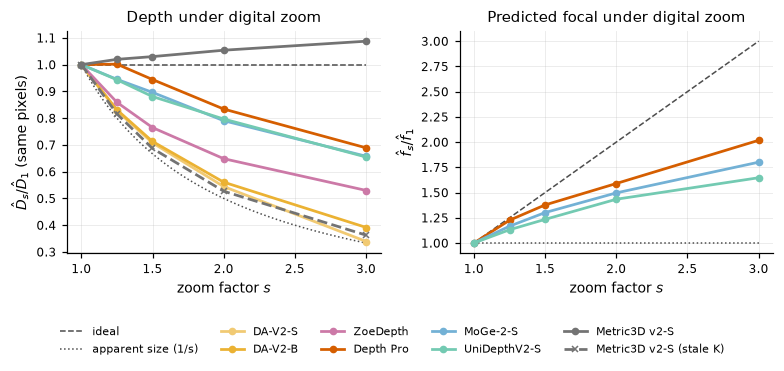

In [4]:
z = df[df.kind == "zoom"].copy()
z["log_fx"] = np.log(z.fx / z.fx_base)
curve = z.groupby(["model", "zoom"]).agg(depth=("log_ratio_self", "median"), focal=("log_fx", "median"),
                                         s=("s_true", "median")).reset_index()

# drawn at its printed size (one column), so the fonts print at 6-7.5 pt
SHORT = {"metric3d-s": "Metric3D v2-S", "metric3d-s-staleK": "Metric3D, stale K"}
with plt.rc_context(SMALL):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(3.35, 1.5))
    ss = np.linspace(1, 3, 50)
    a1.plot(ss, np.ones_like(ss), color="0.3", lw=0.8, ls="--")
    a1.plot(ss, 1 / ss, color="0.3", lw=0.8, ls=":")
    a2.plot(ss, ss, color="0.3", lw=0.8, ls="--")
    a2.plot(ss, np.ones_like(ss), color="0.3", lw=0.8, ls=":")
    kw = dict(fontsize=6, color="0.3")
    for ax_, y, txt in ((a1, 1.0, "ideal"), (a1, 1 / 3, "1/s"), (a2, 3.0, "ideal"), (a2, 1.0, "none")):
        ax_.text(3.1, y, txt, va="center", **kw)
    for m in MAIN:
        c = curve[curve.model == m].sort_values("zoom")
        a1.plot(c.s, np.exp(c.depth), **ps.line(m, lw=1.1, ms=2.5, label=SHORT.get(m, ps.LABEL.get(m, m))))
        if c.focal.notna().all():
            a2.plot(c.s, np.exp(c.focal), **ps.line(m, lw=1.1, ms=2.5))
    a1.set(xlabel="zoom factor $s$", ylabel=r"$\hat D_s / \hat D_1$", title="Depth (same pixels)")
    a2.set(xlabel="zoom factor $s$", ylabel=r"$\hat f_s / \hat f_1$", title="Predicted focal")
    for ax_ in (a1, a2):
        ax_.set(xlim=(0.9, 3.55), xticks=[1, 2, 3])
    h1, l1 = a1.get_legend_handles_labels()
    fig.legend(h1, l1, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.01), columnspacing=0.8, handlelength=1.6,
               handletextpad=0.4)
    fig.tight_layout(rect=(0, 0.2, 1, 1), w_pad=0.6)
    ps.save(fig, "fig2_depth_and_focal_vs_zoom")

## Figure 3: the alpha-beta plane
Each point is one model (median over images, all four sets). The ideal model sits at
(beta, alpha) = (1, 0); a model that reasons from apparent size lies on alpha + beta = 1
(lateral sizes preserved), and a model that ignores the camera at (0, 1).

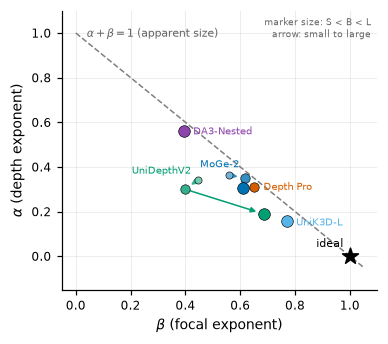

In [5]:
# One path per family, small to large (marker size grows with the model), one label per family.
FAMILIES = {"MoGe-2": ["moge2-s", "moge2-b", "moge2-l"], "UniDepthV2": ["unidepth2-s", "unidepth2-b", "unidepth2-l"]}
SINGLE = ["depthpro", "unik3d-l", "da3-nested"]
# drawn at its printed size (0.78 of a column)
LABEL_AT = {"MoGe-2": ("moge2-b", (-3, 5), "right"), "UniDepthV2": ("unidepth2-s", (-4, 3), "right"),
            "depthpro": ("depthpro", (4, -2), "left"), "unik3d-l": ("unik3d-l", (4, -3), "left"),
            "da3-nested": ("da3-nested", (4, -2), "left")}
SIZE = {"s": 12, "b": 21, "l": 32}
plt.rcParams.update(SMALL)
fig, ax = plt.subplots(figsize=(2.62, 2.33))
b = np.linspace(0, 1.05, 10)
ax.plot(b, 1 - b, color="0.5", lw=0.8, ls="--")
ax.text(0.03, 1.03, r"$\alpha+\beta=1$ (apparent size)", fontsize=6.5, color="0.35", va="top")
ax.scatter([1], [0], marker="*", s=70, color="k", zorder=5)
ax.annotate("ideal", (1, 0), textcoords="offset points", xytext=(-17, 4), fontsize=6.5)
def point(m):
    r = pooled.loc[m] if m in pooled.index else None
    return (r.beta, r.alpha) if r is not None and np.isfinite(r.beta) and np.isfinite(r.alpha) else None
for fam, members in FAMILIES.items():
    pts = [(m, point(m)) for m in members if point(m) is not None]
    for (_, p0), (m1, p1) in zip(pts, pts[1:]):
        ax.annotate("", p1, p0, arrowprops=dict(arrowstyle="-|>", color=ps.colour(m1), lw=0.8, shrinkA=3, shrinkB=4, mutation_scale=5), zorder=3)
    for m, (x, y) in pts:
        ax.scatter(x, y, color=ps.colour(m), s=SIZE[m.split("-")[-1]], edgecolor="k", lw=0.3, zorder=4)
for m in SINGLE:
    if point(m) is not None:
        ax.scatter(*point(m), color=ps.colour(m), s=32 if m != "depthpro" else 21, edgecolor="k", lw=0.3, zorder=4)
for name, (anchor, off, ha) in LABEL_AT.items():
    if point(anchor) is not None:
        colour = ps.colour(FAMILIES[name][-1]) if name in FAMILIES else ps.colour(anchor)
        ax.annotate(ps.LABEL.get(name, name), point(anchor), textcoords="offset points", xytext=off, fontsize=6.5, ha=ha, color=colour)
ax.text(0.03, 0.03, "marker size: S < B < L\narrow: small to large", transform=ax.transAxes, fontsize=6, color="0.35", ha="left", va="bottom")
ax.set(xlabel=r"$\beta$ (focal exponent)", ylabel=r"$\alpha$ (depth exponent)", xlim=(-0.05, 1.1), ylim=(-0.15, 1.1))
fig.tight_layout()
ps.save(fig, "fig3_alpha_beta_plane")
ps.use()  # back to the default sizes for the notebook figures below

## Figure 4: does a bigger model fix it? (model ladder)

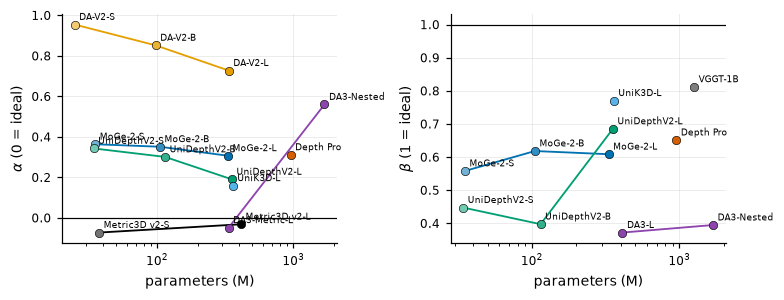

In [6]:
params_f = A.RESULTS / "params.json"
if params_f.exists() and LADDER:
    params = json.loads(params_f.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for ax, metric, ylab in ((axes[0], "alpha", r"$\alpha$ (0 = ideal)"), (axes[1], "beta", r"$\beta$ (1 = ideal)")):
        for fam in ("dav2", "moge2", "unidepth2", "unik3d", "metric3d", "da3", "depthpro", "vggt"):
            ms = [m for m in pooled.index if ps.family(m) == fam and m in params and not m.endswith("staleK")]
            ms = [m for m in ms if np.isfinite(pooled.loc[m, metric])]
            if not ms:
                continue
            ms.sort(key=lambda m: params[m])
            x = [params[m] / 1e6 for m in ms]
            y = [pooled.loc[m, metric] for m in ms]
            ax.plot(x, y, "-", color=ps.colour(ms[-1]), lw=1.2)
            for m, xi, yi in zip(ms, x, y):
                ax.scatter(xi, yi, color=ps.colour(m), s=30, edgecolor="k", lw=0.4, zorder=4)
                ax.annotate(ps.LABEL.get(m, m), (xi, yi), textcoords="offset points", xytext=(3, 3), fontsize=6)
        ax.set(xscale="log", xlabel="parameters (M)", ylabel=ylab)
    axes[0].axhline(0, color="k", lw=0.8)
    axes[1].axhline(1, color="k", lw=0.8)
    fig.tight_layout()
    ps.save(fig, "fig4_model_ladder")

## Per-dataset alpha (with 95% bootstrap CI)

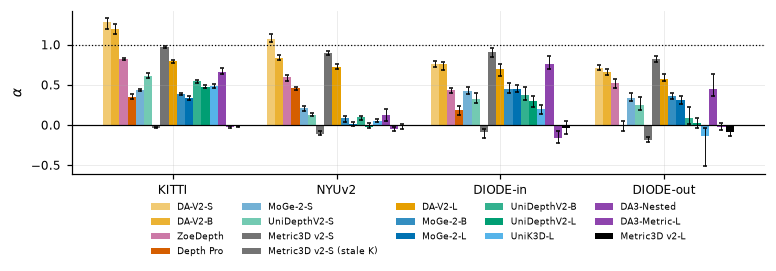

In [7]:
show = [m for m in MAIN + LADDER if m not in RELATIVE]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
width = 0.85 / len(show)
for k, m in enumerate(show):
    s = summ[summ.model == m].set_index("dataset").reindex(A.DATASETS)
    x = np.arange(len(A.DATASETS)) + k * width
    ax.bar(x, s.alpha, width, yerr=[s.alpha - s.alpha_lo, s.alpha_hi - s.alpha], color=ps.colour(m),
           label=ps.LABEL.get(m, m), capsize=1.5, error_kw=dict(lw=0.6))
ax.axhline(0, color="k", lw=0.8)
ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xticks(np.arange(len(A.DATASETS)) + 0.425 - width / 2, [A.PRETTY_DS[d] for d in A.DATASETS])
ax.set_ylabel(r"$\alpha$")
ax.legend(fontsize=6, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
ps.save(fig, "figS_alpha_per_dataset")